# Hiding a bump under a carpet: a quasi-conformal cloak

Transformation optics turns a coordinate map into a material. If a map
$w = (u, v)(x, y)$ takes the physical plane to a "virtual" plane, a
medium with

$$\varepsilon_z = \det K, \qquad \mu_{\parallel} = \frac{J J^{\mathsf T}}{\det J},
\qquad K = \frac{\partial(u, v)}{\partial(x, y)},\; J = K^{-1}$$

reproduces in the physical plane exactly what vacuum does in the virtual
plane, for $E$ along $z$ (Ward and Pendry 1996, Pendry, Schurig and Smith
2006). Cloaks built this way need extreme, anisotropic and magnetic
materials. Li and Pendry (2008) found a way out for a **carpet cloak**: a
bump on a mirror, covered with a medium that makes it look like a flat
mirror. If the map from the region above the bump to the rectangle above a
flat mirror is *conformal*, $J J^{\mathsf T} = \det J\,I$, the medium is
isotropic and non-magnetic, a plain graded index

$$n^2 = \det K = \left|\frac{\mathrm dw}{\mathrm dz}\right|^2 .$$

An exact conformal map between the two regions does not exist (their
conformal modules differ), but one that lets the points *slide* along the
mirror is almost conformal; dropping the small leftover anisotropy leaves
a dielectric that could be written into silicon or silicon nitride, which
is how the first optical carpet cloaks were built (Valentine et al. 2009,
Gabrielli et al. 2009).

This notebook

1. computes the map by solving two Laplace equations (`pyoptics.cloak`)
   for three choices of boundary conditions, and checks the index against
   first-order perturbation theory;
2. sends a Gaussian beam onto a flat mirror, the bare bump and the cloaked
   bump with the FDFD solver (`pyoptics.fdfd` with a graded permittivity),
   as field maps and angular spectra, the flat mirror against the analytic
   reflection;
3. traces rays through the isotropic cloak (`pyoptics.grin`): the dropped
   anisotropy leaves a lateral shift of the reflected beam (Zhang, Chan and
   Wu 2010), which the FDFD beams show too;
4. shows where the cloak breaks down: wavelength, angle of incidence,
   clipping the index at $n \ge 1$, and the other polarization;
5. explains why the ideal cylindrical cloak of Pendry et al. is out of
   reach of this solver.

The gradient-index lenses of notebook 77 and the FDFD basics of notebook 66
are the background; nothing here repeats them. Lengths are in units of the
design wavelength $\lambda = 1$ (the cloak itself has no length scale: an
ideal transformation medium works at every wavelength).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import cloak, fdfd, fdtd

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "image.origin": "lower"})
t_start = time.time()
DEG = np.pi/180
RAY = "#2fb6c9"
COL = {"flat": "0.2", "bare": "C3", "cloak": "C0", "clipped": "C1", "analytic": "#f0c419"}

## 1. The map: two Laplace problems

The physical region is the box $|x| < a$ between the bump $y = h(x)$ and
the top $y = H$; the virtual region is the rectangle $|u| < a$,
$0 < v < H$. `CarpetCloak` takes $u$ and $v$ as harmonic functions of
$(x, y)$ (the inverse of Winslow's elliptic grid generation) with

| | $v$ | $u$ |
|---|---|---|
| mirror (bump) | $v = 0$ | $\partial_n u = 0$ (points slide along the mirror) |
| top | $v = H$ | $u = x$ ("mirror", "fixed") or $\partial_n u = 0$ ("sliding") |
| sides | $v = y$ ("mirror", "fixed") or $\partial_n v = 0$ ("sliding") | $u = \pm a$ |

and "fixed" also pins the mirror points, $u = x$ on the bump. Both
equations are solved with second-order finite differences on a grid fitted
to the bump, $\eta = (y - h)/(H - h)$. The index is $n^2 = \det K$, and the
anisotropy that is dropped is $\alpha = \sigma_1/\sigma_2 \ge 1$, the
ratio of the singular values of $K$ (the ratio of the two principal
indices of the full medium; 1 for a conformal map).

The bump is $h = 0.5\cos^2(\pi x/3)$ for $|x| < 1.5$, a cloak $18 \times 5$
wavelengths. With the outer boundary fixed ("mirror") the map is the
identity on the edge of the cloak, as it must be for the outside to see
vacuum; "sliding" everywhere (as in Li and Pendry) is closer to conformal
inside but slides the top edge sideways, which an observer outside sees.

In [2]:
h0, w_b, a, H = 0.5, 1.5, 9.0, 5.0
bump = cloak.cos2_bump(h0, w_b)
t0 = time.time()
maps = {b: cloak.CarpetCloak(bump, a, H, boundary=b) for b in ("sliding", "mirror", "fixed")}
print("three maps: {:.1f} s".format(time.time() - t0))
for b, c in maps.items():
    du, dv = c.boundary_mismatch()
    n = np.sqrt(c.n2_grid)
    print(f"{b:8s}: n from {n.min():.3f} to {n.max():.3f}, anisotropy alpha <= {c.alpha.max():.4f}, "
          f"top edge slides by {du:.3f}, sides by {dv:.1e}")
cl = maps["mirror"]

three maps: 3.5 s
sliding : n from 0.704 to 1.678, anisotropy alpha <= 1.0214, top edge slides by 0.043, sides by 1.6e-03
mirror  : n from 0.702 to 1.674, anisotropy alpha <= 1.0331, top edge slides by 0.000, sides by 1.6e-11
fixed   : n from 0.835 to 1.298, anisotropy alpha <= 1.6854, top edge slides by 0.000, sides by 1.6e-11


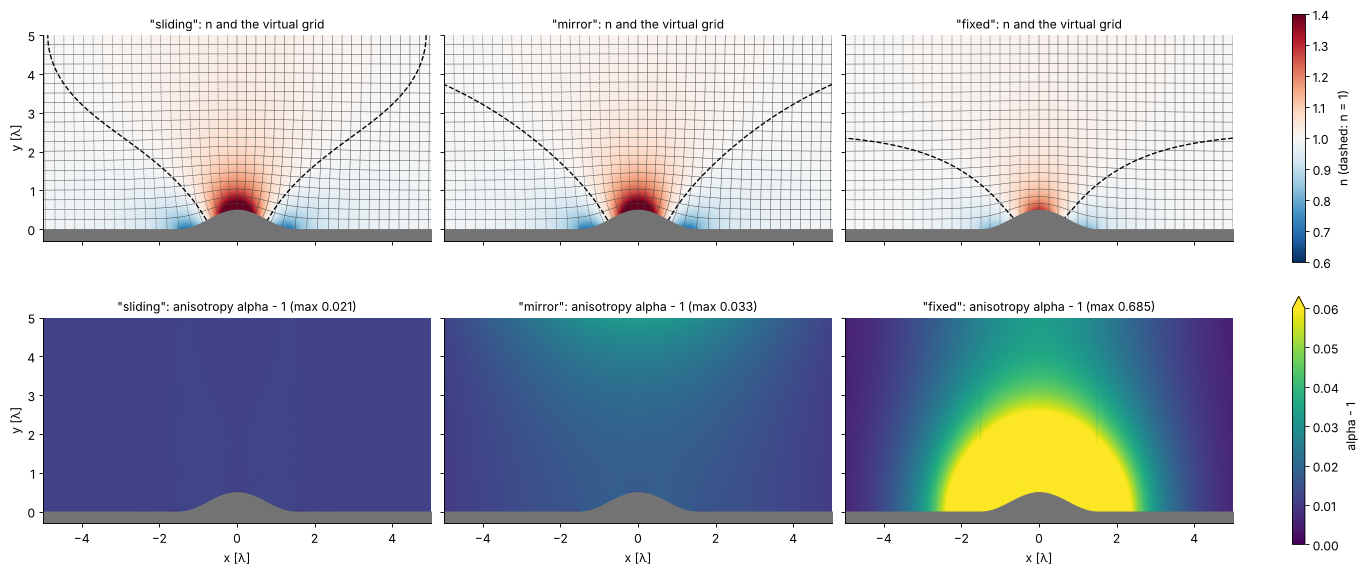

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(17, 7.2), layout="constrained", sharex=True, sharey=True)
xb = np.linspace(-a, a, 721)
for k, (b, c) in enumerate(maps.items()):
    ax = axes[0, k]
    im = ax.pcolormesh(c.x, c.y, np.sqrt(c.n2_grid), cmap="RdBu_r", vmin=0.6, vmax=1.4, shading="gouraud")
    ax.contour(c.x, c.y, c.u, levels=np.arange(-a + 0.25, a, 0.25), colors="0.25", linewidths=0.4)
    ax.contour(c.x, c.y, c.v, levels=np.arange(0.25, H, 0.25), colors="0.25", linewidths=0.4)
    ax.contour(c.x, c.y, np.sqrt(c.n2_grid), levels=[1.0], colors="k", linewidths=1.2, linestyles="--")
    ax.set_title(f'"{b}": n and the virtual grid', fontsize=11)
    ax2 = axes[1, k]
    im2 = ax2.pcolormesh(c.x, c.y, c.alpha - 1, cmap="viridis", vmin=0, vmax=0.06, shading="gouraud")
    ax2.set_title(f'"{b}": anisotropy alpha - 1 (max {c.alpha.max() - 1:.3f})', fontsize=11)
    for axx in (ax, ax2):
        axx.fill_between(xb, -0.3, bump(xb), color="0.45")
        axx.set_xlim(-5, 5); axx.set_ylim(-0.3, H); axx.set_aspect("equal")
    ax2.set_xlabel("x [λ]")
axes[0, 0].set_ylabel("y [λ]"); axes[1, 0].set_ylabel("y [λ]")
fig.colorbar(im, ax=axes[0], label="n (dashed: n = 1)", shrink=0.9)
fig.colorbar(im2, ax=axes[1], label="alpha - 1", shrink=0.9, extend="max");

The lines of constant $u$ and $v$ are the flat mirror's square grid as the
cloak sees it: squeezed above the bump (there $n > 1$, up to 1.7) and
stretched at its feet ($n < 1$, down to 0.70). With sliding boundaries the
cells stay squares to within 2 % everywhere, but the top edge moves by
0.04 λ (and the sides by 0.002 λ). Pinning the outer edge ("mirror") forces the mismatch of
the conformal modules into the top centre, where $\alpha$ reaches 1.033;
pinning the mirror points too ("fixed") gives up conformality right at the
bump ($\alpha = 1.69$): the grid lines no longer cross at right angles.
The index ranges are similar to those of the cloaks of Li and Pendry and of
Gabrielli et al.

### First-order theory

For a small bump write $v = y - \varphi$, $u = x - \chi$ in an infinite
strip. To first order in $h$, $\varphi = h$ and $\partial_y\chi = -h'$ on
the mirror, $\varphi = \partial_y \chi = 0$ on the top, so
$\varphi$ and $\chi$ are harmonic conjugates: the map is conformal at
first order, and

$$n^2 = 1 - \partial_x\chi - \partial_y\varphi = 1 + 2\sum_k |k|\,\hat h_k\,
\frac{\cosh k(H - y)}{\sinh |k|H}\,e^{ikx} .$$

On the mirror this is $1 + 2|\partial_x| h$ for a deep cloak: a positive
index bump above the top, negative lobes at the feet whose integral
cancels (`CarpetCloak.linear_n2`). The difference from the solved map is
of second order in $h_0$; the anisotropy, a mismatch of the conformal
modules, of first order in the area of the bump, spread over the cloak.

n^2 - linear theory ~ h0^1.96,   alpha - 1 ~ h0^0.98


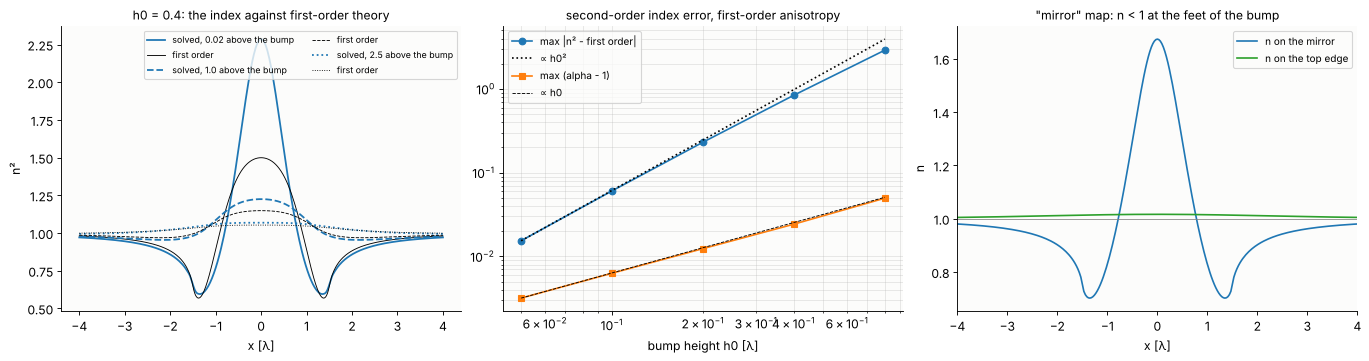

In [4]:
heights = np.array([0.05, 0.1, 0.2, 0.4, 0.8])
dev, an = [], []
for hh in heights:
    c = cloak.CarpetCloak(cloak.cos2_bump(hh, w_b), a, H, n_xi=301, n_eta=61)
    sl = (slice(90, 211, 2), slice(None, None, 2))       # |x| < 3
    dev.append(np.abs(c.n2_grid[sl] - c.linear_n2(c.x[sl], c.y[sl])).max())
    an.append(c.alpha.max() - 1)
    if hh == 0.4:
        c04 = c
dev, an = np.array(dev), np.array(an)
p_dev = np.polyfit(np.log(heights[:3]), np.log(dev[:3]), 1)[0]
p_an = np.polyfit(np.log(heights[:3]), np.log(an[:3]), 1)[0]
print(f"n^2 - linear theory ~ h0^{p_dev:.2f},   alpha - 1 ~ h0^{p_an:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), layout="constrained")
xs1 = np.linspace(-4, 4, 401)
for y0, ls in ((0.02, "-"), (1.0, "--"), (2.5, ":")):
    yy = c04.bump(xs1) + y0
    axes[0].plot(xs1, c04.permittivity(xs1, yy), "C0", ls=ls, lw=1.6, label=f"solved, {y0} above the bump")
    axes[0].plot(xs1, c04.linear_n2(xs1, yy), "k", ls=ls, lw=0.8, label="first order")
axes[0].set_xlabel("x [λ]"); axes[0].set_ylabel("n²"); axes[0].legend(fontsize=8, ncol=2)
axes[0].set_title("h0 = 0.4: the index against first-order theory", fontsize=11)
axes[1].loglog(heights, dev, "o-", label="max |n² - first order|")
axes[1].loglog(heights, dev[0]*(heights/heights[0])**2, "k:", label="∝ h0²")
axes[1].loglog(heights, an, "s-", label="max (alpha - 1)")
axes[1].loglog(heights, an[0]*heights/heights[0], "k--", lw=0.8, label="∝ h0")
axes[1].set_xlabel("bump height h0 [λ]"); axes[1].legend(fontsize=9); axes[1].grid(alpha=0.3, which="both")
axes[1].set_title("second-order index error, first-order anisotropy", fontsize=11)
# where n < 1: the stretched feet
c = cl
axes[2].plot(c.xi, np.sqrt(c.n2_grid[:, 0]), "C0", label="n on the mirror")
axes[2].plot(c.xi, np.sqrt(c.n2_grid[:, -1]), "C2", label="n on the top edge")
axes[2].axhline(1, color="0.5", lw=0.7)
axes[2].set_xlim(-4, 4); axes[2].set_xlabel("x [λ]"); axes[2].set_ylabel("n"); axes[2].legend(fontsize=9)
axes[2].set_title('"mirror" map: n < 1 at the feet of the bump', fontsize=11);

## 2. Waves: a Gaussian beam on the mirror

The FDFD solver of notebook 66 takes the cloak as a graded background,
`fdfd.Simulation(permittivity=cl.permittivity)`, for $E$ along $z$ (the
polarization for which $n^2 = \varepsilon_z$ is all that is needed; the
magnetic part is the dropped anisotropy). The mirror is a metal with
$n = 100i$, the bump a polygon of it.

The beam comes from a line of sources above the cloak: a current sheet
$K(x)$ radiates $\hat u_k = -\omega \hat K_k/(2k_y)$ each way, so choosing
$\hat K_k = -2k_y \hat u_k/\omega$ (with the $k_y$ and the Green's function
of the grid, `cloak.beam_sources`) launches exactly the wanted angular
spectrum, a Gaussian beam with a waist of 2 λ on the mirror at 40°.
The wave the sheet sends upwards leaves through the PML. A run without any
mirror gives the incident field, which is subtracted on a line between the
sources and the cloak to leave the reflected beam; its angular spectrum is
compared, as a complex function of the angle, with that of the flat
mirror:

$$\epsilon = \frac{\lVert S - S_{\text{flat}}\rVert}{\lVert S_{\text{flat}}\rVert}, \qquad
S_{\text{flat}}^{\text{exact}}(\theta) = -\hat u_{\text{inc}}(\theta) .$$

In [5]:
Y_SRC, Y_M = H + 1.2, H + 0.4         # source line, measuring line
xb_poly = np.linspace(-w_b, w_b, 301)
MIRRORS = {False: fdtd.Polygon([(-16, -3), (16, -3), (16, 0), (-16, 0)]),
           True: fdtd.Polygon([(-16, -3), (16, -3), (16, 0)] + [(x, bump(x)) for x in xb_poly[::-1]] + [(-16, 0)])}
_cloaks = {"cloak": cl}


def experiment(wl, theta, waist=2.0, mode="Ez", cases=("flat", "bare", "cloak"), full=False, n_min=None):
    """Free space, flat mirror, bare bump, cloaked bump (and the cloak with
    n clipped at n_min): reflected field on the line y = Y_M, its angular
    spectrum, the centroid of the reflected beam, and the error against the
    flat mirror."""
    dx = min(0.04, wl/25)
    grid = fdtd.Grid((30.0, H + 3.2), dx, center=(0.0, (H + 1.6)/2))
    metal = fdtd.Medium.from_index(0.0, 100.0, wavelength=wl)
    xs, ys = fdfd.Simulation(grid, mode=mode).coords(mode)
    y_src = ys[np.argmin(np.abs(ys - Y_SRC))]
    jm = np.argmin(np.abs(ys - Y_M))
    srcs, u_inc = cloak.beam_sources(xs[np.abs(xs) < 14], y_src, wl, theta, waist, spacing=dx)
    if n_min is not None and n_min not in _cloaks:
        _cloaks[n_min] = cloak.CarpetCloak(bump, a, H, boundary="mirror", n_min=n_min)
    conf = {"free": ([], None), "flat": ([(MIRRORS[False], metal)], None),
            "bare": ([(MIRRORS[True], metal)], None),
            "cloak": ([(MIRRORS[True], metal)], cl.permittivity),
            "clipped": ([(MIRRORS[True], metal)], _cloaks.get(n_min, cl).permittivity)}
    fields = {}
    for k in ("free",) + tuple(cases):
        st, perm = conf[k]
        fields[k] = fdfd.Simulation(grid, st, mode=mode, permittivity=perm).solve(wl, srcs).main
    line = {k: fields[k][:, jm] - fields["free"][:, jm] for k in cases}
    th, _ = cloak.angular_spectrum(line[cases[0]], xs, wl)
    S = {k: cloak.angular_spectrum(line[k], xs, wl)[1] for k in cases}
    I = {k: np.abs(line[k])**2 for k in cases}
    cen = {k: np.sum(xs*I[k])/np.sum(I[k]) for k in cases}
    err = {k: np.linalg.norm(S[k] - S["flat"])/np.linalg.norm(S["flat"]) for k in cases}
    return dict(x=xs, y=ys, jm=jm, u_inc=u_inc, line=line, theta=th, S=S, err=err,
                shift={k: cen[k] - cen["flat"] for k in cases}, fields=fields if full else None)


t0 = time.time()
r40 = experiment(1.0, 40*DEG, full=True)
print("four FDFD solves ({} unknowns each): {:.0f} s".format(r40["fields"]["free"].size, time.time() - t0))
xs, ys = r40["x"], r40["y"]
_, S_exact = cloak.angular_spectrum(-r40["u_inc"](xs, -ys[r40["jm"]]*np.ones_like(xs)), xs, 1.0)
e_ex = np.linalg.norm(r40["S"]["flat"] - S_exact)/np.linalg.norm(S_exact)
print(f"flat mirror against the exact reflection: {100*e_ex:.1f} %")
for k in ("bare", "cloak"):
    print(f"{k:6s}: spectrum error {100*r40['err'][k]:.0f} %, beam centroid shifted by {r40['shift'][k]:+.2f} λ")

four FDFD solves (153750 unknowns each): 10 s
flat mirror against the exact reflection: 0.2 %
bare  : spectrum error 133 %, beam centroid shifted by +0.02 λ
cloak : spectrum error 17 %, beam centroid shifted by -0.33 λ


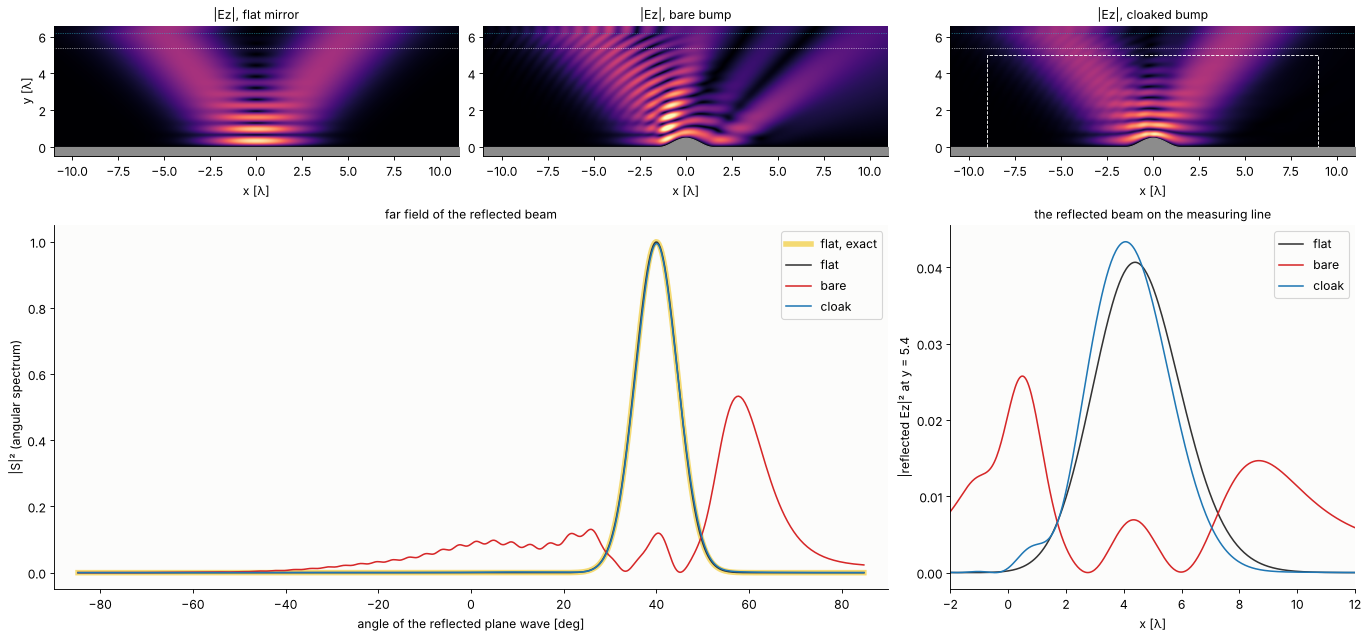

In [6]:
fig = plt.figure(figsize=(17, 8.2), layout="constrained")
gs = fig.add_gridspec(2, 3, height_ratios=[0.6, 1])
xx = np.linspace(-16, 16, 2001)
below_src = ys < Y_SRC - 0.3
vmax = 1.05*np.abs(r40["fields"]["flat"][:, below_src]).max()
for k, (name, title) in enumerate((("flat", "flat mirror"), ("bare", "bare bump"), ("cloak", "cloaked bump"))):
    ax = fig.add_subplot(gs[0, k])
    u = r40["fields"][name]
    ax.imshow(np.abs(u).T, extent=(xs[0], xs[-1], ys[0], ys[-1]), cmap="magma", vmax=vmax,
              interpolation="bilinear")
    ax.fill_between(xx, -1, bump(xx) if name != "flat" else 0*xx, color="0.55")
    if name == "cloak":
        ax.plot([-a, -a, a, a], [0, H, H, 0], color="w", lw=0.8, ls="--")
    ax.axhline(Y_SRC, color=RAY, lw=0.6, ls=":"); ax.axhline(Y_M, color="w", lw=0.6, ls=":")
    ax.set_xlim(-11, 11); ax.set_ylim(-0.5, H + 1.6); ax.set_aspect("equal")
    ax.set_title(f"|Ez|, {title}", fontsize=11); ax.set_xlabel("x [λ]")
fig.axes[0].set_ylabel("y [λ]")
ax = fig.add_subplot(gs[1, :2])
th = r40["theta"]/DEG
ax.plot(th, np.abs(S_exact)**2, color=COL["analytic"], lw=5, alpha=0.6, label="flat, exact")
for k in ("flat", "bare", "cloak"):
    ax.plot(th, np.abs(r40["S"][k])**2, color=COL[k], lw=1.4, label=k)
ax.set_xlabel("angle of the reflected plane wave [deg]"); ax.set_ylabel("|S|² (angular spectrum)")
ax.set_xlim(-90, 90); ax.legend(); ax.set_title("far field of the reflected beam", fontsize=11)
ax = fig.add_subplot(gs[1, 2])
for k in ("flat", "bare", "cloak"):
    ax.plot(xs, np.abs(r40["line"][k])**2, color=COL[k], lw=1.4, label=k)
ax.set_xlim(-2, 12); ax.set_xlabel("x [λ]"); ax.set_ylabel(f"|reflected Ez|² at y = {Y_M}")
ax.set_title("the reflected beam on the measuring line", fontsize=11); ax.legend();

The bare bump breaks the beam up: its slopes of up to ±0.52 rad tilt the
local reflection by up to twice that, the specular lobe drops to an eighth,
and the light goes into a lobe near 57° and a broad fan towards normal
incidence. Under the carpet the bump is gone: the beam leaves as from the
flat mirror, with its intensity spectrum nearly unchanged. The residual
17 % is mostly a phase, a sideways displacement of the beam by a third of a
wavelength, which the next section explains with rays. The source, FDFD
and measuring scheme reproduce the exact flat-mirror reflection to 0.2 %,
so the comparison is not limited by the numerics.

## 3. Rays: the lateral shift of the dropped anisotropy

The isotropic cloak and the full anisotropic one share the index
$\sqrt{\varepsilon_z\mu}$ only where $\alpha = 1$. Rays in the isotropic
medium (traced with `pyoptics.grin`, refracted where the index jumps at the
top edge, reflected on the bump: `CarpetCloak.trace`) bend a little too
much or too little, and leave displaced and slightly tilted. Zhang, Chan
and Wu (2010) pointed out that such a lateral shift, comparable to the
height of the bump and independent of the wavelength, gives the
quasi-conformal cloak away to anyone with a narrow enough beam. The
Gaussian-weighted mean of the ray shifts is compared with the shift of the
FDFD beam's centroid.

 angle | FDFD centroid shift | rays (weighted) | largest ray tilt
    0° |      -0.000 λ       |    +0.000 λ     |   0.91°
   20° |      -0.182 λ       |    -0.194 λ     |   0.79°
   40° |      -0.334 λ       |    -0.309 λ     |   0.83°
   60° |      -0.255 λ       |    -0.220 λ     |   0.57°


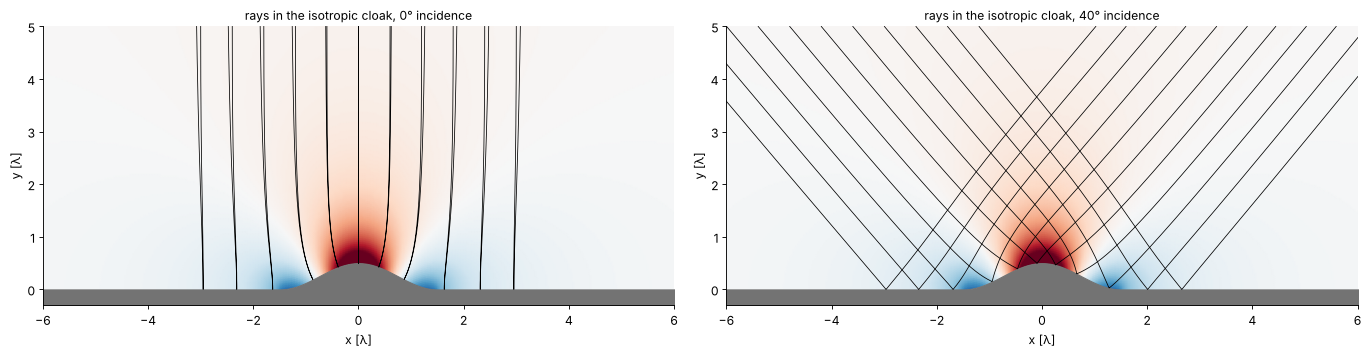

In [7]:
angles = np.array([0, 20, 40, 60])
fd_shift, ray_shift, ray_dev = [], [], []
fig, axes = plt.subplots(1, 2, figsize=(17, 4.6), layout="constrained")
for th_i in angles:
    r = r40 if th_i == 40 else experiment(1.0, th_i*DEG)
    fd_shift.append(r["shift"]["cloak"])
    q = np.linspace(-3, 3, 41)                      # where the rays meet the plane y = 0
    x0 = q - Y_SRC*np.tan(th_i*DEG)
    x_end, ex, paths = cl.trace(x0, Y_SRC, th_i*DEG, Y_M)
    flat_end = x0 + (Y_SRC + Y_M)*np.tan(th_i*DEG)
    wgt = np.exp(-2*(q*np.cos(th_i*DEG)/2.0)**2)
    ray_shift.append(np.sum(wgt*(x_end - flat_end))/wgt.sum())
    ray_dev.append(np.abs(ex - th_i*DEG).max()/DEG)
    if th_i in (0, 40):
        ax = axes[0 if th_i == 0 else 1]
        ax.pcolormesh(cl.x, cl.y, np.sqrt(cl.n2_grid), cmap="RdBu_r", vmin=0.6, vmax=1.4, shading="gouraud")
        for p in paths[::4]:
            ax.plot(p[:, 0], p[:, 1], color="k", lw=0.7)
        ax.fill_between(xb, -0.3, bump(xb), color="0.45")
        ax.set_xlim(-6, 6); ax.set_ylim(-0.3, H); ax.set_aspect("equal")
        ax.set_title(f"rays in the isotropic cloak, {th_i}° incidence", fontsize=11)
        ax.set_xlabel("x [λ]"); ax.set_ylabel("y [λ]")
print(" angle | FDFD centroid shift | rays (weighted) | largest ray tilt")
for t_, f_, r_, d_ in zip(angles, fd_shift, ray_shift, ray_dev):
    print(f"  {t_:3d}° |      {f_:+.3f} λ       |    {r_:+.3f} λ     |   {d_:.2f}°")

Rays and waves agree on the shift: none at normal incidence (by symmetry;
the rays only fan out by under a degree, a weak diverging lens), and
−0.2 to −0.33 λ at oblique incidence, of the order of the bump height,
with rays and waves within 0.04 λ. Because the shift is a fixed length, a
beam a few wavelengths wide at a long wavelength hardly notices it, while
a beam as narrow as the wavelength allows does at a short one: this, not
dispersion of the material, is what limits an isotropic carpet cloak at
short wavelengths.

## 4. Where the cloak breaks down

### Wavelength

The geometry stays fixed (a 0.5 high bump, a waist of 2 on the mirror at
40°), the wavelength runs from 0.6 to 3; the grid follows with 25 points
per wavelength. A run with the index clipped at $n \ge 1$ (no stretched
regions, all $n < 1$ set to 1) is shown alongside.

wavelength sweep: 236 s
λ = 0.6: ε bare 106 %, cloak  18 %, clipped 104 %, cloak in Hz  25 %; shift -0.34
λ = 0.8: ε bare 109 %, cloak  21 %, clipped  94 %, cloak in Hz  37 %; shift -0.33
λ = 1.0: ε bare 133 %, cloak  17 %, clipped  75 %, cloak in Hz  35 %; shift -0.33
λ = 1.4: ε bare 137 %, cloak  14 %, clipped  50 %, cloak in Hz  38 %; shift -0.32
λ = 2.0: ε bare 113 %, cloak  12 %, clipped  32 %, cloak in Hz  27 %; shift -0.31
λ = 3.0: ε bare  81 %, cloak   9 %, clipped  18 %, cloak in Hz  38 %; shift -0.27


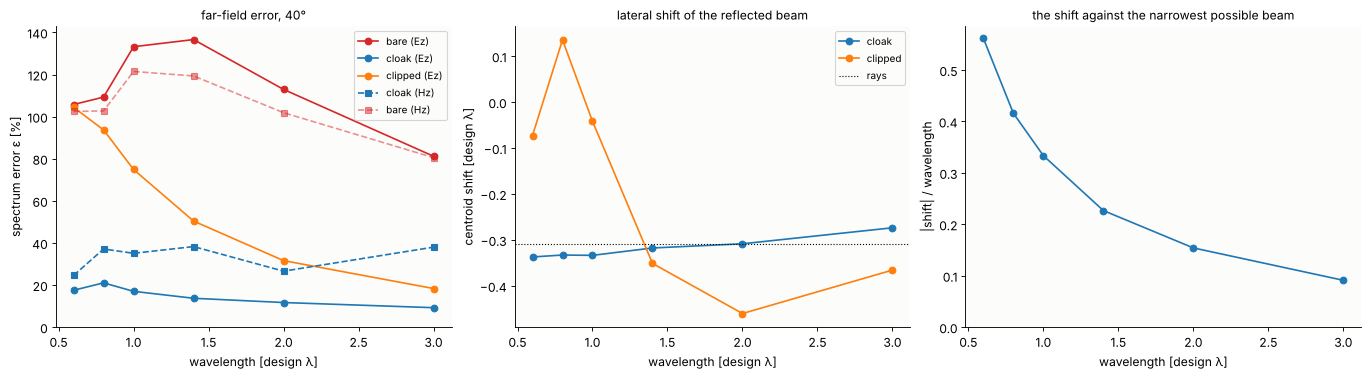

In [8]:
wls = np.array([0.6, 0.8, 1.0, 1.4, 2.0, 3.0])
t0 = time.time()
sweep = [experiment(wl, 40*DEG, cases=("flat", "bare", "cloak", "clipped"), n_min=1.0) for wl in wls]
sweep_hz = [experiment(wl, 40*DEG, mode="Hz", cases=("flat", "bare", "cloak")) for wl in wls]
print("wavelength sweep: {:.0f} s".format(time.time() - t0))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
for k in ("bare", "cloak", "clipped"):
    axes[0].plot(wls, [100*r["err"][k] for r in sweep], "o-", color=COL[k], label=k + " (Ez)")
axes[0].plot(wls, [100*r["err"]["cloak"] for r in sweep_hz], "s--", color=COL["cloak"], label="cloak (Hz)")
axes[0].plot(wls, [100*r["err"]["bare"] for r in sweep_hz], "s--", color=COL["bare"], alpha=0.5, label="bare (Hz)")
axes[0].set_xlabel("wavelength [design λ]"); axes[0].set_ylabel("spectrum error ε [%]")
axes[0].set_ylim(0, None); axes[0].legend(fontsize=9); axes[0].set_title("far-field error, 40°", fontsize=11)
for k in ("cloak", "clipped"):
    axes[1].plot(wls, [r["shift"][k] for r in sweep], "o-", color=COL[k], label=k)
axes[1].axhline(ray_shift[2], color="k", ls=":", lw=1, label="rays")
axes[1].set_xlabel("wavelength [design λ]"); axes[1].set_ylabel("centroid shift [design λ]")
axes[1].legend(fontsize=9); axes[1].set_title("lateral shift of the reflected beam", fontsize=11)
axes[2].plot(wls, [-r["shift"]["cloak"]/wl for r, wl in zip(sweep, wls)], "o-", color=COL["cloak"])
axes[2].set_ylim(0, None)
axes[2].set_xlabel("wavelength [design λ]"); axes[2].set_ylabel("|shift| / wavelength")
axes[2].set_title("the shift against the narrowest possible beam", fontsize=11)
for wl, r, rh in zip(wls, sweep, sweep_hz):
    print(f"λ = {wl:.1f}: ε bare {100*r['err']['bare']:3.0f} %, cloak {100*r['err']['cloak']:3.0f} %, "
          f"clipped {100*r['err']['clipped']:3.0f} %, cloak in Hz {100*rh['err']['cloak']:3.0f} %; "
          f"shift {r['shift']['cloak']:+.2f}")

The cloak works over the whole factor of five in wavelength, as a
transformation medium without dispersion should: its error stays at 9 to
21 %, against 80 to 140 % for the bare bump, and its lateral shift stays
at the ray value in absolute length. With the beam waist fixed, the shift
costs the same phase across the beam's angular spectrum at every
wavelength ($k\,\Delta x\cos\theta \cdot \lambda/(\pi w) = 2\Delta x\cos\theta/w$),
so ε hardly changes; a beam as narrow as the wavelength allows resolves
the shift better and better towards short wavelengths (right). At long
wavelengths the bump itself matters less (it is only λ/6 high at λ = 3).

Clipping the index at 1 is a different kind of error: the medium is no
longer a transformation of vacuum, and what is left is an optical path
error of fixed length, which costs more phase at short wavelengths. At
λ = 0.6 the clipped cloak is no better than the bare bump.

The same index for the other polarization ($H$ along $z$, a non-magnetic
substitute for $\mu_z = n^2$) obeys $\nabla\cdot(n^{-2}\nabla H) + k^2 H = 0$
instead of $\nabla^2 H + k^2 n^2 H = 0$. The two share the eikonal, so rays
cannot tell them apart, but the extra term $\nabla n^{-2}\cdot\nabla H$
scatters where the index changes within a wavelength, at the feet and the
top of the bump. That doubles the error (25 to 38 %); over this range the
gradients never become slow on the scale of λ, and the trend towards the
ray limit is not yet visible.

### Angle of incidence and how far n may be clipped

angle and clipping sweeps: 115 s
n_min = 0.75:  0.1 % of the cloak clipped, ε = 17 %, shift -0.33 λ
n_min = 0.80:  0.2 % of the cloak clipped, ε = 17 %, shift -0.33 λ
n_min = 0.85:  0.4 % of the cloak clipped, ε = 17 %, shift -0.34 λ
n_min = 0.90:  0.9 % of the cloak clipped, ε = 19 %, shift -0.36 λ
n_min = 0.95:  2.4 % of the cloak clipped, ε = 33 %, shift -0.34 λ
n_min = 1.00: 61.0 % of the cloak clipped, ε = 75 %, shift -0.04 λ


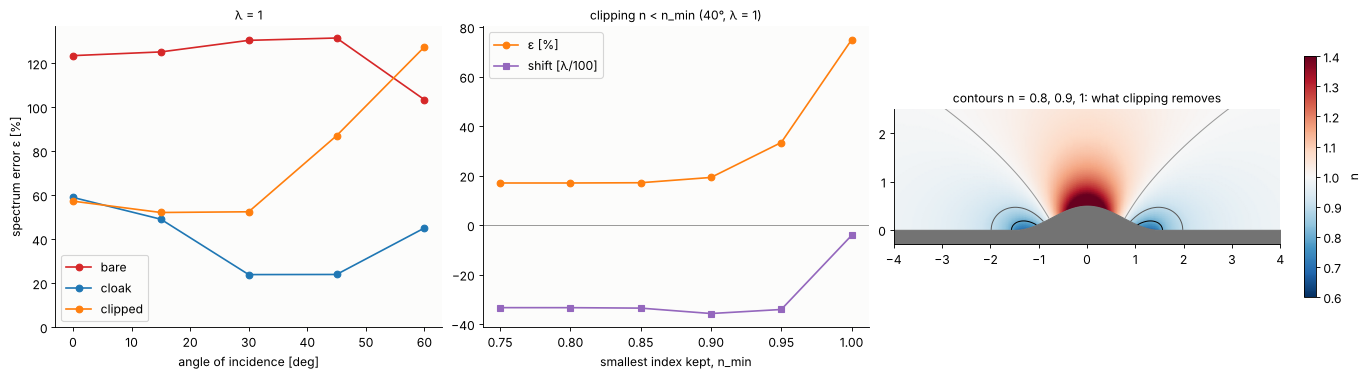

In [9]:
angles2 = np.array([0, 15, 30, 45, 60])
t0 = time.time()
ang = [experiment(1.0, t*DEG, cases=("flat", "bare", "cloak", "clipped"), n_min=1.0) for t in angles2]
nmins = np.array([0.75, 0.8, 0.85, 0.9, 0.95, 1.0])
clip = [experiment(1.0, 40*DEG, cases=("flat", "clipped"), n_min=nm) for nm in nmins]
print("angle and clipping sweeps: {:.0f} s".format(time.time() - t0))
frac = [np.mean(cl.n2_grid < nm**2) for nm in nmins]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
for k in ("bare", "cloak", "clipped"):
    axes[0].plot(angles2, [100*r["err"][k] for r in ang], "o-", color=COL[k], label=k)
axes[0].set_xlabel("angle of incidence [deg]"); axes[0].set_ylabel("spectrum error ε [%]")
axes[0].legend(); axes[0].set_ylim(0, None); axes[0].set_title("λ = 1", fontsize=11)
axes[1].plot(nmins, [100*r["err"]["clipped"] for r in clip], "o-", color=COL["clipped"], label="ε [%]")
axes[1].plot(nmins, [100*r["shift"]["clipped"] for r in clip], "s-", color="C4", label="shift [λ/100]")
axes[1].axhline(0, color="0.5", lw=0.7)
axes[1].set_xlabel("smallest index kept, n_min"); axes[1].legend()
axes[1].set_title("clipping n < n_min (40°, λ = 1)", fontsize=11)
im = axes[2].pcolormesh(cl.x, cl.y, np.sqrt(cl.n2_grid), cmap="RdBu_r", vmin=0.6, vmax=1.4, shading="gouraud")
axes[2].contour(cl.x, cl.y, np.sqrt(cl.n2_grid), levels=[0.8, 0.9, 1.0], colors=["k", "0.35", "0.6"],
                linewidths=0.9)
axes[2].fill_between(xb, -0.3, bump(xb), color="0.45")
axes[2].set_xlim(-4, 4); axes[2].set_ylim(-0.3, 2.5); axes[2].set_aspect("equal")
axes[2].set_title("contours n = 0.8, 0.9, 1: what clipping removes", fontsize=11)
fig.colorbar(im, ax=axes[2], label="n", shrink=0.8)
for nm, r, f in zip(nmins, clip, frac):
    print(f"n_min = {nm:.2f}: {100*f:4.1f} % of the cloak clipped, ε = {100*r['err']['clipped']:.0f} %, "
          f"shift {r['shift']['clipped']:+.2f} λ")

The cloak helps at every angle, most at 30 to 45° (24 %); at normal
incidence the beam crosses the column of raised index above the bump twice
and comes back slightly diverged (the rays above fan out by 0.9°), which
the complex error counts as 59 %, still half that of the bare bump.

Clipping shows how the index below 1 is spread: the deep minima at the
feet ($n < 0.9$) fill under 1 % of the cloak and can go with almost no
cost, but the mismatch of the conformal modules pulls $n$ slightly below 1
over 61 % of the cloak (outside the dashed contours in the first figure),
and removing all of it raises ε from 17 to 75 %. In practice the whole
cloak is put into a host medium instead: scaling all indices by
$n_h \ge 1/n_{\min}$ (here 1.43) keeps the map intact, at the price of an
observer who sits in the host (the carpet cloaks of Valentine et al. and
Gabrielli et al. lived in silicon or silicon nitride slab waveguides). The
FDFD only scales the wavelength by $n_h$ then, which the wavelength sweep
above already covers.

## 5. Why not Pendry's cylindrical cloak?

The ideal cloak of Pendry, Schurig and Smith compresses the disk $r < b$
into the annulus $a < r < b$, $r' = a + r(b - a)/b$. For $E$ along $z$ it
needs

$$\mu_r = \frac{r - a}{r},\quad \mu_\varphi = \frac{r}{r - a},\quad
\varepsilon_z = \left(\frac{b}{b - a}\right)^2\frac{r - a}{r},$$

and for $H$ along $z$ the same with $\varepsilon \leftrightarrow \mu$. Even the
"reduced" parameters of Schurig et al. (2006), which keep the rays but give
up the impedance match, keep one tensor:
$\mu_r = ((r - a)/r)^2$, $\mu_\varphi = 1$ with $\varepsilon_z = (b/(b-a))^2$
(Ez), or $\varepsilon_r = ((r-a)/r)^2 (b/(b-a))^2$, $\varepsilon_\varphi = (b/(b-a))^2$,
$\mu_z = 1$ (Hz). The FDFD solver has no permeability at all in the Ez
mode, and in the Hz mode only a diagonal $(\varepsilon_x, \varepsilon_y)$ on
the Yee grid; a tensor that is diagonal in $(r, \varphi)$ has off-diagonal
$\varepsilon_{xy} = (\varepsilon_r - \varepsilon_\varphi)\sin\varphi\cos\varphi$
in $(x, y)$, which needs the interpolated cross terms of an anisotropic
FDFD (and $\mu_r \to 0$, $\mu_\varphi \to \infty$ at the inner edge, which
no grid resolves). A radial map cannot be conformal (it would have to be
$\log$-like and changes the topology), which is exactly why the carpet,
with a mirror to hide behind, is the cloak an isotropic dielectric can
build. The parameters show the problem:

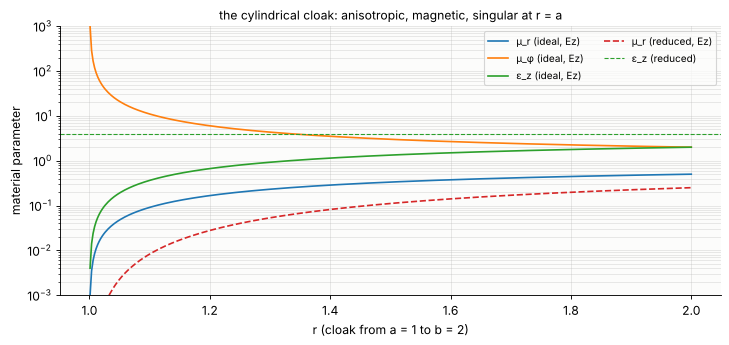

In [10]:
ra, rb = 1.0, 2.0
r = np.linspace(ra*1.001, rb, 400)
fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
ax.semilogy(r, (r - ra)/r, label="μ_r (ideal, Ez)")
ax.semilogy(r, r/(r - ra), label="μ_φ (ideal, Ez)")
ax.semilogy(r, (rb/(rb - ra))**2*(r - ra)/r, label="ε_z (ideal, Ez)")
ax.semilogy(r, ((r - ra)/r)**2, "--", label="μ_r (reduced, Ez)")
ax.axhline((rb/(rb - ra))**2, color="C2", ls="--", lw=1, label="ε_z (reduced)")
ax.set_xlabel("r (cloak from a = 1 to b = 2)"); ax.set_ylabel("material parameter")
ax.set_ylim(1e-3, 1e3); ax.legend(fontsize=9, ncol=2); ax.grid(alpha=0.3, which="both")
ax.set_title("the cylindrical cloak: anisotropic, magnetic, singular at r = a", fontsize=11);

## Summary

- A carpet cloak needs only the index $n^2 = \det\,\partial(u, v)/\partial(x, y)$
  of a nearly conformal map; two Laplace solves give it. The index agrees
  with first-order perturbation theory to second order in the bump height;
  the leftover anisotropy is first order in the bump area. Fixing the outer
  edge (and letting points slide only along the mirror) is what keeps the
  outside unaware of the cloak; the 18 × 5 λ cloak of a 0.5 λ bump needs
  $0.70 \le n \le 1.67$ with $\alpha \le 1.033$.
- FDFD with the graded permittivity hides the bump: the reflected beam's
  angular spectrum differs from the flat mirror's by 17 %, mostly in
  phase, against 133 % for the bare bump (40°, λ = 1). The flat-mirror
  reference matches the exact reflection to 0.2 %.
- The dropped anisotropy displaces the reflected beam by 0.2 to 0.33 λ at
  oblique incidence; rays traced through the isotropic index give the same
  shift as the FDFD beams to within 0.04 λ. It is a fixed length, so the
  cloak works from 0.6 to 3 λ, but a narrow beam at a short wavelength
  sees it.
- Clipping $n < 0.9$ costs nothing, clipping all $n < 1$ (61 % of the
  cloak) quadruples the error and fails at short wavelengths; a host index
  of $1/n_{\min}$ avoids it. The other polarization, with the same index as
  a non-magnetic substitute, doubles the error.
- The ideal cylindrical cloak needs an anisotropic, magnetic and singular
  medium, which this scalar FDFD cannot represent.

In [11]:
print("total run time: {:.0f} s".format(time.time() - t_start))

total run time: 413 s


## References

J. Li and J. B. Pendry, "Hiding under the carpet: a new strategy for
cloaking", Phys. Rev. Lett. 101, 203901 (2008).

J. B. Pendry, D. Schurig and D. R. Smith, "Controlling electromagnetic
fields", Science 312, 1780-1782 (2006).

A. J. Ward and J. B. Pendry, "Refraction and geometry in Maxwell's
equations", J. Mod. Opt. 43, 773-793 (1996).

U. Leonhardt, "Optical conformal mapping", Science 312, 1777-1780 (2006).

D. Schurig, J. J. Mock, B. J. Justice, S. A. Cummer, J. B. Pendry, A. F.
Starr and D. R. Smith, "Metamaterial electromagnetic cloak at microwave
frequencies", Science 314, 977-980 (2006).

J. Valentine, J. Li, T. Zentgraf, G. Bartal and X. Zhang, "An optical
cloak made of dielectrics", Nature Mater. 8, 568-571 (2009).

L. H. Gabrielli, J. Cardenas, C. B. Poitras and M. Lipson, "Silicon
nanostructure cloak operating at optical frequencies", Nature Photon. 3,
461-463 (2009).

B. Zhang, T. Chan and B.-I. Wu, "Lateral shift makes a ground-plane cloak
detectable", Phys. Rev. Lett. 104, 233903 (2010).

J. F. Thompson, Z. U. A. Warsi and C. W. Mastin, "Numerical Grid
Generation: Foundations and Applications", North-Holland (1985), chapter 5.

R. C. Rumpf, "Electromagnetic and Photonic Simulation for the Beginner:
Finite-Difference Frequency-Domain in MATLAB", Artech House (2022).